# Red Neuronal Profunda

Este ejemplo muestra la implementación de una red neuronal profunda (Deep Neural Network: DNN) con la siguiente arquitectura:
- Una capa de entrada
- L-1 capas ocultas (cada una con activación ReLU)
- 1 capa de salida con activación sigmoidea

In [1]:
# Se requiere numpy y matplotlib
import numpy as np
import matplotlib.pyplot as plt

# Red neuronal
from deep_nn import DeepNeuralNetwork

# Funciones de ayuda para cargar datos y gráficos
from funciones_ayuda import generar_datos_petalos, plot_decision_boundary

## 1. Lectura de los datos ##

Los datos corresponden a dos clases distribuidas en forma de pétalos.

Tamaño de X: (2, 400)
Tamaño de Y: (1, 400)
Número de instancias de entrenamiento: 400


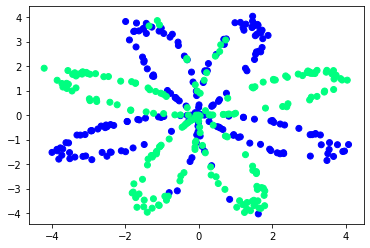

In [2]:
# cargar los datos
X, Y = generar_datos_petalos()

# Mostrar tamaños
n = X.shape[1]   # Número de instancias
d = X.shape[0]   # Número de atributos por instancia
print ('Tamaño de X:', str(X.shape))
print ('Tamaño de Y:', str(Y.shape))
print ('Número de instancias de entrenamiento:', str(n))

# Visualizar los datos
plt.scatter(X[0,:], X[1,:], c=Y.flatten(), cmap='winter');

## 2. Red Neuronal

### Entrenamiento

Se usará un modelo de red neuronal profunda con 4 capas: 3 capas ocultas y una capa de salida. Las capas ocultas tendrán 20, 7 y 5 neuronas, respectivamente, y la capa de salida solo tendrá una neurona ya que se trabaja con un clasificador binario.

In [3]:
# Modelo con 4 capas cada una con 20, 7, 5 y 1 neurona, respectivamente
dim_capas = [d, 20, 7, 5, 1]

# Creación del modelo
modelo = DeepNeuralNetwork(dim_layers=dim_capas, num_iter=10000, learning_rate=0.008, verbose=True)

# Entrenamiento de la red neuronal
modelo.fit(X, Y)

Costo luego de la iteración 0: 0.6923
Costo luego de la iteración 1000: 0.478
Costo luego de la iteración 2000: 0.3729
Costo luego de la iteración 3000: 0.3311
Costo luego de la iteración 4000: 0.3074
Costo luego de la iteración 5000: 0.2888
Costo luego de la iteración 6000: 0.2727
Costo luego de la iteración 7000: 0.2595
Costo luego de la iteración 8000: 0.2479
Costo luego de la iteración 9000: 0.2376


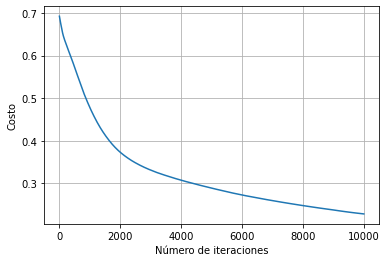

In [4]:
# Graficar la función de costo
plt.plot(modelo.costo)
plt.grid()
plt.xlabel("Número de iteraciones"); plt.ylabel("Costo");

### Predicciones

Se realizará la predicción en las instancias de entrenamiento.

Exactitud: 89.25 %


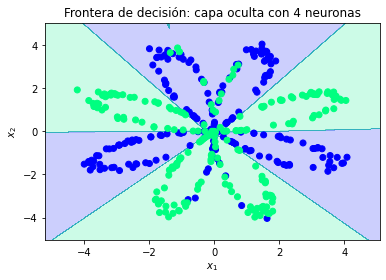

In [5]:
# Predicciones para X
Ypred = modelo.predict(X)

# Exactitud en el conjunto de entrenamiento
exactitud = (np.dot(Y, Ypred.T) + np.dot(1-Y, 1-Ypred.T))/float(Y.size)*100
print("Exactitud: {} %".format(exactitud.item() ))

# Gráfico de la frontera de decisión
plot_decision_boundary(modelo, X, Y)
plt.title("Frontera de decisión: capa oculta con {} neuronas".format(str(4)));